# 03 · Modelling (Phase 6)

**E0 — Leakage check:** same model, random split vs speaker-independent split.
**E1 — Within-corpus benchmark:** 4 models × 3 feature sets × 2 corpora, speaker-independent 5-fold CV.

Leak-free by construction: scaling, hyperparameter tuning and WavLM layer choice all happen **inside training folds**
(inner 3-fold speaker-grouped CV). Test folds are touched only for scoring.

Metric: **UAR** (unweighted average recall = mean of per-emotion recall), plus macro-F1 and accuracy. Chance UAR = 16.7% (6 classes).

Results are cached in `results/phase6/`, so re-running skips finished configurations (set `REDO = True` to recompute).
⏱ First full run: roughly 30–60 min on a MacBook (SVM and MLP on CREMA-D are the slow parts).

In [1]:
import sys, json, time
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from src.models import (load_corpus, select_layer, run_within_corpus, leakage_check,
                        CLASSES, DEFAULT_LAYER)

REDO = False
SEED = 0
CORPORA = ["ravdess", "cremad"]
FEATURE_SETS = ["egemaps", "wavlm", "fusion"]
MODELS = ["logreg", "svm", "lgbm", "mlp"]

OUT = PROJECT_ROOT / "results" / "phase6"; OUT.mkdir(parents=True, exist_ok=True)
FIG_DIR = PROJECT_ROOT / "results" / "figures"
BLUE, ORANGE, AQUA, YELLOW, INK, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})

data = {c: load_corpus(c) for c in CORPORA}
for c, d in data.items():
    print(f"{c}: {len(d['y'])} labelled clips, {len(set(d['groups']))} speakers, "
          f"eGeMAPS {d['egemaps'].shape}, WavLM {d['wavlm'].shape}")

ravdess: 1056 labelled clips, 24 speakers, eGeMAPS (1056, 88), WavLM (1056, 13, 768)
cremad: 7442 labelled clips, 91 speakers, eGeMAPS (7442, 88), WavLM (7442, 13, 768)


## E0 · How much does speaker leakage inflate accuracy?
Logistic regression, identical settings. *Random split* lets the same speaker appear in training and test; *speaker split* does not.
WavLM uses layer 6, fixed in advance (middle layer, per P4/P7), so no tuning is involved.

In [2]:
rows = []
for c in CORPORA:
    for fs, layer in [("egemaps", None), ("wavlm", DEFAULT_LAYER)]:
        r = leakage_check(data[c], fs, layer, seed=SEED)
        rows.append({"corpus": c, "features": fs, **r,
                     "inflation_pts": 100 * (r["random_split_uar"] - r["speaker_split_uar"])})
e0 = pd.DataFrame(rows)
e0.to_csv(OUT / "e0_leakage.csv", index=False)
e0.round(3)

,corpus,features,random_split_uar,speaker_split_uar,inflation_pts
0,ravdess,egemaps,0.632,0.539,9.288
1,ravdess,wavlm,0.918,0.840,7.812
2,cremad,egemaps,0.523,0.508,1.480
3,cremad,wavlm,0.742,0.724,1.749


## Choosing the WavLM layer (inside training folds only)
For each outer fold, every layer is scored by an inner speaker-grouped CV **on that fold's training data**; the best layer is used for that fold.
The curve below averages those *inner* scores, so it never involves test data.

ravdess: 13s
ravdess chosen layer per fold: {0: 6, 1: 6, 2: 5, 3: 5, 4: 5}
cremad: 38s
cremad chosen layer per fold: {0: 6, 1: 6, 2: 5, 3: 7, 4: 7}


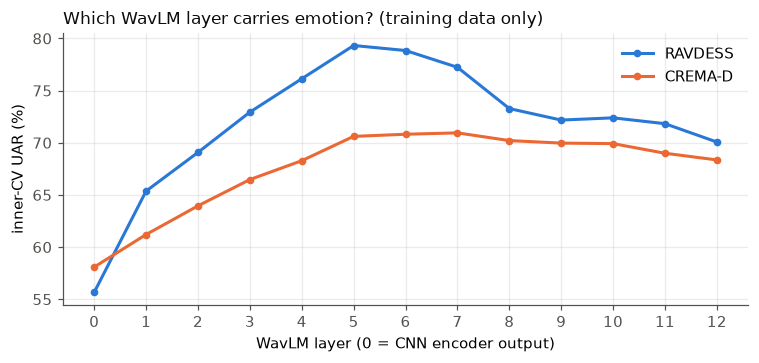

In [3]:
layers, profiles = {}, {}
for c in CORPORA:
    f = OUT / f"layers_{c}.json"
    if f.exists() and not REDO:
        saved = json.loads(f.read_text())
        layers[c] = {int(k): v for k, v in saved["layers"].items()}; profiles[c] = saved["profile"]
    else:
        d, t0 = data[c], time.time()
        layers[c], curves = {}, []
        for k in sorted(np.unique(d["folds"])):
            tr = d["folds"] != k
            best, uars = select_layer(d["wavlm"][tr], d["y"][tr], d["groups"][tr])
            layers[c][int(k)] = best; curves.append(uars)
        profiles[c] = np.mean(curves, axis=0).tolist()
        f.write_text(json.dumps({"layers": layers[c], "profile": profiles[c]}))
        print(f"{c}: {time.time()-t0:.0f}s")
    print(c, "chosen layer per fold:", layers[c])

fig, ax = plt.subplots(figsize=(7, 3.4))
for c, col in zip(CORPORA, [BLUE, ORANGE]):
    ax.plot(range(13), np.array(profiles[c]) * 100, marker="o", ms=4, lw=2, color=col,
            label="RAVDESS" if c == "ravdess" else "CREMA-D")
ax.set_xlabel("WavLM layer (0 = CNN encoder output)"); ax.set_ylabel("inner-CV UAR (%)")
ax.set_title("Which WavLM layer carries emotion? (training data only)", loc="left", color=INK, fontsize=11)
ax.set_xticks(range(13)); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "p6_wavlm_layer_profile.png", bbox_inches="tight"); plt.show()

## E1 · Within-corpus benchmark

In [4]:
all_folds = []
for c in CORPORA:
    for fs in FEATURE_SETS:
        for m in MODELS:
            tag = f"{c}_{fs}_{m}"
            f_csv, f_oof = OUT / f"e1_{tag}.csv", OUT / f"e1_{tag}_oof.npy"
            if f_csv.exists() and not REDO:
                res = pd.read_csv(f_csv)
            else:
                t0 = time.time()
                res, oof = run_within_corpus(data[c], fs, m, seed=SEED, layers_per_fold=layers[c])
                res.to_csv(f_csv, index=False); np.save(f_oof, oof)
                print(f"{tag:28s} UAR {res['uar'].mean():.3f}  ({time.time()-t0:.0f}s)")
            res.insert(0, "model", m); res.insert(0, "features", fs); res.insert(0, "corpus", c)
            all_folds.append(res)
folds_df = pd.concat(all_folds, ignore_index=True)
folds_df.to_csv(OUT / "e1_all_folds.csv", index=False)

ravdess_egemaps_logreg       UAR 0.554  (0s)
ravdess_egemaps_svm          UAR 0.524  (0s)
ravdess_egemaps_lgbm         UAR 0.539  (11s)
ravdess_egemaps_mlp          UAR 0.514  (1s)
ravdess_wavlm_logreg         UAR 0.810  (1s)
ravdess_wavlm_svm            UAR 0.785  (2s)
ravdess_wavlm_lgbm           UAR 0.767  (90s)
ravdess_wavlm_mlp            UAR 0.786  (2s)
ravdess_fusion_logreg        UAR 0.822  (1s)
ravdess_fusion_svm           UAR 0.788  (2s)
ravdess_fusion_lgbm          UAR 0.763  (103s)
ravdess_fusion_mlp           UAR 0.813  (2s)
cremad_egemaps_logreg        UAR 0.515  (2s)
cremad_egemaps_svm           UAR 0.528  (14s)
cremad_egemaps_lgbm          UAR 0.538  (23s)
cremad_egemaps_mlp           UAR 0.520  (5s)
cremad_wavlm_logreg          UAR 0.738  (7s)
cremad_wavlm_svm             UAR 0.734  (101s)
cremad_wavlm_lgbm            UAR 0.703  (220s)
cremad_wavlm_mlp             UAR 0.725  (13s)
cremad_fusion_logreg         UAR 0.741  (9s)
cremad_fusion_svm            UAR 0.734  (109

In [5]:
def pooled_uar(c, fs, m):
    from sklearn.metrics import balanced_accuracy_score
    oof = np.load(OUT / f"e1_{c}_{fs}_{m}_oof.npy")
    return balanced_accuracy_score(data[c]["y"], oof)

summary = (folds_df.groupby(["corpus", "features", "model"])
           .agg(uar_mean=("uar", "mean"), uar_std=("uar", "std"),
                f1_mean=("macro_f1", "mean"), acc_mean=("accuracy", "mean"))
           .reset_index())
summary["uar_pooled"] = [pooled_uar(r.corpus, r.features, r.model) for r in summary.itertuples()]
summary.to_csv(OUT / "e1_summary.csv", index=False)
for c in CORPORA:
    t = summary[summary.corpus == c].pivot(index="model", columns="features", values="uar_mean")
    print(f"\n{c.upper()} — mean UAR over 5 speaker-independent folds (%)")
    print((t[FEATURE_SETS] * 100).round(1).to_string())


RAVDESS — mean UAR over 5 speaker-independent folds (%)
features  egemaps  wavlm  fusion
model                           
lgbm         53.9   76.8    76.3
logreg       55.4   81.0    82.2
mlp          51.4   78.6    81.3
svm          52.4   78.5    78.8

CREMAD — mean UAR over 5 speaker-independent folds (%)
features  egemaps  wavlm  fusion
model                           
lgbm         53.8   70.3    70.2
logreg       51.5   73.8    74.1
mlp          52.0   72.5    73.1
svm          52.8   73.4    73.4


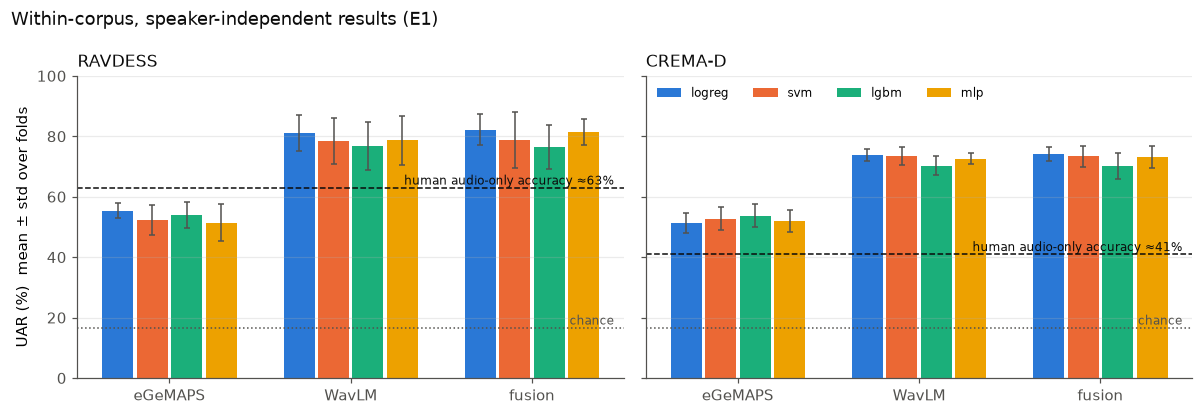

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
colours = {"logreg": BLUE, "svm": ORANGE, "lgbm": AQUA, "mlp": YELLOW}
x = np.arange(len(FEATURE_SETS)); w = 0.19
human = {"ravdess": 63, "cremad": 41}
for ax, c in zip(axes, CORPORA):
    s = summary[summary.corpus == c]
    for i, m in enumerate(MODELS):
        r = s[s.model == m].set_index("features").loc[FEATURE_SETS]
        ax.bar(x + (i - 1.5) * w, r["uar_mean"] * 100, w * 0.9, yerr=r["uar_std"] * 100,
               color=colours[m], label=m, error_kw={"elinewidth": 1, "ecolor": MUTED, "capsize": 2})
    ax.axhline(100 / 6, color=MUTED, ls=":", lw=1); ax.text(2.45, 100 / 6 + 1, "chance", color=MUTED, fontsize=8, ha="right")
    ax.axhline(human[c], color=INK, ls="--", lw=1)
    ax.text(2.45, human[c] + 1, f"human audio-only accuracy ≈{human[c]}%", color=INK, fontsize=8, ha="right")
    ax.set_xticks(x, ["eGeMAPS", "WavLM", "fusion"]); ax.set_ylim(0, 100)
    ax.set_title("RAVDESS" if c == "ravdess" else "CREMA-D", loc="left", color=INK, fontsize=11)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("UAR (%)  mean ± std over folds"); axes[1].legend(frameon=False, ncol=4, loc="upper left", fontsize=8)
fig.suptitle("Within-corpus, speaker-independent results (E1)", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "p6_within_corpus_uar.png", bbox_inches="tight"); plt.show()

## Confusion matrices — best configuration per corpus (out-of-fold predictions)

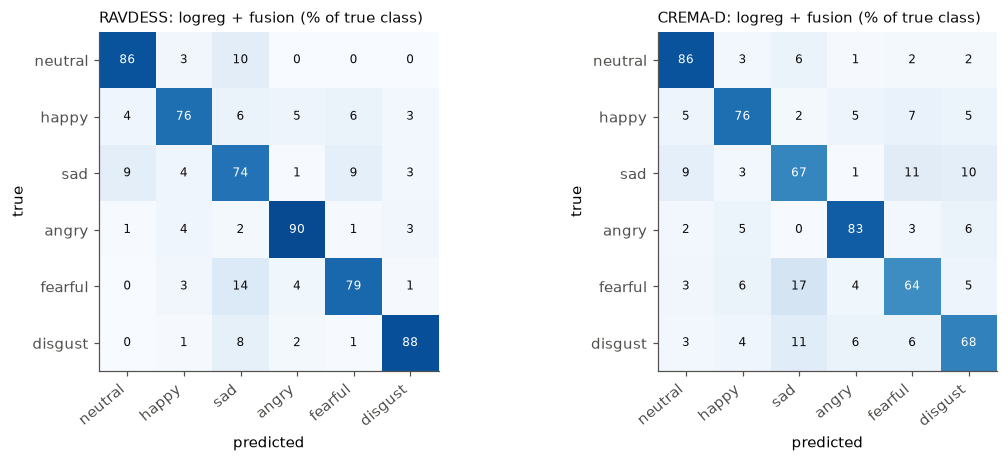

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.3))
best = {}
for ax, c in zip(axes, CORPORA):
    s = summary[summary.corpus == c].sort_values("uar_mean", ascending=False).iloc[0]
    best[c] = {"features": s.features, "model": s.model, "uar_mean": round(float(s.uar_mean), 4)}
    oof = np.load(OUT / f"e1_{c}_{s.features}_{s.model}_oof.npy")
    cm = confusion_matrix(data[c]["y"], oof, normalize="true") * 100
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=100)
    for i in range(6):
        for j in range(6):
            ax.text(j, i, f"{cm[i, j]:.0f}", ha="center", va="center", fontsize=8,
                    color="white" if cm[i, j] > 55 else INK)
    ax.set_xticks(range(6), CLASSES, rotation=40, ha="right"); ax.set_yticks(range(6), CLASSES)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.grid(False)
    ax.set_title(f"{'RAVDESS' if c=='ravdess' else 'CREMA-D'}: {s.model} + {s.features} (% of true class)",
                 loc="left", color=INK, fontsize=10)
fig.tight_layout(); fig.savefig(FIG_DIR / "p6_confusion_best.png", bbox_inches="tight"); plt.show()

In [8]:
result = {"e0_leakage": e0.round(4).to_dict(orient="records"),
          "wavlm_layers_per_fold": {c: layers[c] for c in CORPORA},
          "wavlm_layer_profile_inner_uar": {c: [round(v, 4) for v in profiles[c]] for c in CORPORA},
          "e1_summary": summary.round(4).to_dict(orient="records"),
          "best_per_corpus": best}
(PROJECT_ROOT / "results" / "phase6_summary.json").write_text(json.dumps(result, indent=2, default=str))
print(json.dumps(best, indent=2))

{
  "ravdess": {
    "features": "fusion",
    "model": "logreg",
    "uar_mean": 0.8223
  },
  "cremad": {
    "features": "fusion",
    "model": "logreg",
    "uar_mean": 0.7413
  }
}
